#  Projet Big Data : Analyse de l'evolution et l'instabilité du climat urbain mondial (1743-2013)
Yamina Benferlou

BUT Science des Données - Parcours EMS 31

2025/2026

---

## 1. Introduction

Le climat urbain constitue aujourd'hui l'un des laboratoires les plus complexes pour comprendre les impacts du dérèglement climatique. Si la hausse des températures moyennes est une réalité largement documentée, les dynamiques fines qui régissent cette mutation restent, à l'échelle des métropoles mondiales, un champ d'analyse statistique ouvert.

Cette étude se propose de décrypter ces mécanismes à travers l'exploitation d'une base de données climatologique, comptant 1 048 576 enregistrements permettant une analyse temporelle de l'évolution des températures terrestres. Ce jeu de données est structuré autour de sept colonnes fondamentales : la date (dt), la température moyenne (AverageTemperature) et son incertitude (AverageTemperatureUncertainty), ainsi que des descripteurs géographiques précis tels que la ville (City), le pays (Country), et les coordonnées (Latitude et Longitude).

**Problématique :** Au-delà de la simple hausse des températures mondiales, dans quelle mesure l'analyse historique révèle-t-elle un réchauffement urbain profondément asymétrique, marqué par des déséquilibres saisonniers, une aggravation des extrêmes et de fortes inégalités géographiques ?

### 2. Annonce du Plan

Pour démontrer cette asymétrie et répondre à cette problématique, notre étude se structure autour de six axes d'analyse :

* **Axe 1 :** Tendance globale
* **Axe 2 :** Dynamiques saisonnières et asymétrie hémisphérique
* **Axe 3 :** Instabilité Climatique
* **Axe 4 :** Analyse des vulnérabilités urbaines
* **Axe 5 :** Empreinte thermique






In [ ]:
# 1. Installation de PySpark dans l'environnement Colab
!pip install pyspark -q

# 2. Importation des modules nécessaires
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, year, month, to_date, avg, stddev, desc, round
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql.window import Window
import pandas as pd
import plotly.express as px
from pyspark.sql import functions as F
import plotly.graph_objects as go
import requests
import plotly.figure_factory as ff
from sklearn.linear_model import LinearRegression
import plotly.graph_objects as go
import numpy as np
from scipy import stats



# 3. Initialisation de la session Spark
spark = SparkSession.builder \
    .appName("Projet_Climat_YaminaB") \
    .master("local[*]") \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate()



### Importation et nettoyage de la base de données

In [ ]:
from pyspark.sql.functions import col, year, month, to_date, when, substring, concat_ws, mean

df_raw = spark.read.csv(
    "GlobalLandTemperaturesByCity.csv",
    header=True,
    sep=";",
    inferSchema=False
)

# 1. VERIFICATION DU FORMAT DES DONNEES
df_temp = df_raw.withColumn("dt_str", col("dt").cast("string")) \
                 .withColumn("dt_texte_repare",
                     when(col("dt_str").contains("/"),
                          concat_ws("-",
                                    substring(col("dt_str"), 7, 4),
                                    substring(col("dt_str"), 4, 2),
                                    substring(col("dt_str"), 1, 2)
                          )
                     ).otherwise(col("dt_str"))
                 ) \
                 .withColumn("dt_final", to_date(col("dt_texte_repare"), "yyyy-MM-dd")) \
                 .withColumn("AverageTemperature", col("AverageTemperature").cast("float")) \
                 .withColumn("Year", year(col("dt_final"))) \
                 .withColumn("Month", month(col("dt_final")))
                 # <-- J'ai supprimé la ligne .filter() qui enlevait les données avant 1850 !

# 2. L'IMPUTATION DES VALEURS MANQUANTES
# On calcule la moyenne de toutes les températures valides
moyenne_globale = df_temp.select(mean(col("AverageTemperature"))).collect()[0][0]

# On remplace tous les valeurs nulles par cette moyenne
df_clean = df_temp.fillna({"AverageTemperature": moyenne_globale})
df_clean.cache()

df_clean.show(5)
print(df_clean.columns)

+----------+------------------+-----------------------------+------+-------+--------+---------+----------+---------------+----------+----+-----+
|        dt|AverageTemperature|AverageTemperatureUncertainty|  City|Country|Latitude|Longitude|    dt_str|dt_texte_repare|  dt_final|Year|Month|
+----------+------------------+-----------------------------+------+-------+--------+---------+----------+---------------+----------+----+-----+
|1743-11-01|             6.068|           1.7369999999999999|Ã…rhus|Denmark|  57.05N|   10.33E|1743-11-01|     1743-11-01|1743-11-01|1743|   11|
|1743-12-01|         17.928991|                         NULL|Ã…rhus|Denmark|  57.05N|   10.33E|1743-12-01|     1743-12-01|1743-12-01|1743|   12|
|1744-01-01|         17.928991|                         NULL|Ã…rhus|Denmark|  57.05N|   10.33E|1744-01-01|     1744-01-01|1744-01-01|1744|    1|
|1744-02-01|         17.928991|                         NULL|Ã…rhus|Denmark|  57.05N|   10.33E|1744-02-01|     1744-02-01|1744-02-

In [ ]:
# Nettoyage robuste pour éviter l'erreur DateTimeException
df = df_clean.withColumn("Year",
    F.when(F.col("dt").contains("-"), F.split(F.col("dt"), "-")[0])
     .otherwise(F.split(F.col("dt"), "/")[2]).cast("int")
)
df = df_clean.withColumn("Month",
    F.when(F.col("dt").contains("-"), F.split(F.col("dt"), "-")[1])
     .otherwise(F.split(F.col("dt"), "/")[1]).cast("int")
)

# Conversion nécessaire pour les calculs
df = df_clean.withColumn("AverageTemperature", F.col("AverageTemperature").cast("float"))


## Axe 1 : Tendance Globale

Ici, nous isolons la trajectoire de fond du réchauffement climatique. Pour éviter d'être induits en erreur par les variations météorologiques d'une année à l'autre (phénomènes ponctuels, cycles naturels), nous appliquons une moyenne mobile sur 10 ans. Cette méthode permet de filtrer le bruit annuel et de révéler l'accélération thermique que subissent les métropoles mondiales depuis le début de l'ère industrielle.

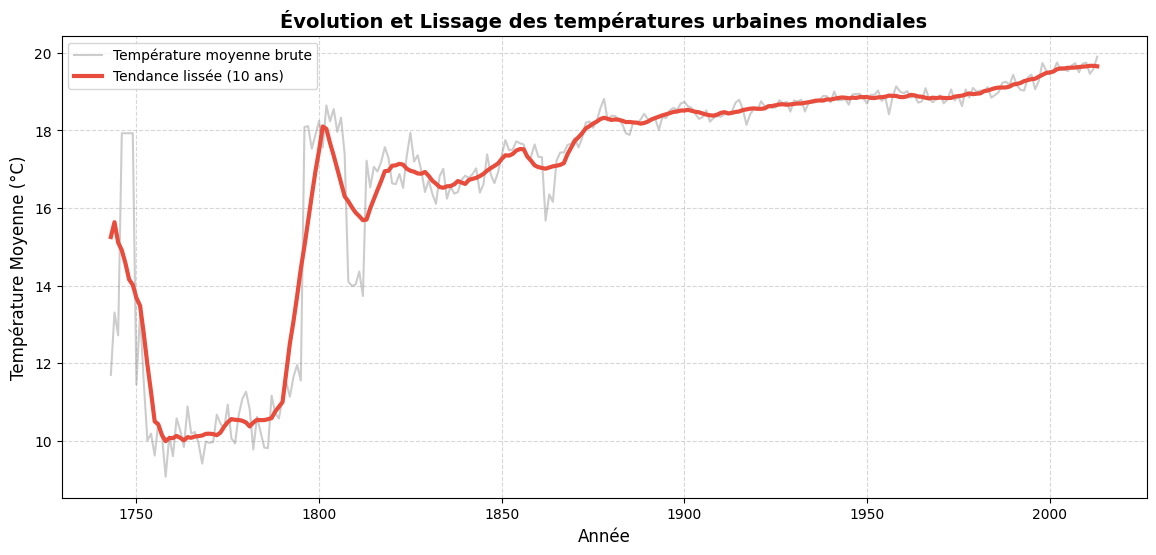

In [ ]:
# 1. Agrégation annuelle brute
df_trend = df_clean.groupBy("Year").agg(round(avg("AverageTemperature"), 3).alias("Temp_Annuelle"))

# 2. Moyenne mobile sur +/- 5 ans (Ce qui donne un total de 10 années)
windowSpec = Window.orderBy("Year").rowsBetween(-5, 5)
df_trend = df_trend.withColumn("Moyenne_Mobile_10ans", round(avg("Temp_Annuelle").over(windowSpec), 3))

# 3. Visualisation
pdf_trend = df_trend.toPandas().dropna()

plt.figure(figsize=(14, 6))
plt.plot(pdf_trend['Year'], pdf_trend['Temp_Annuelle'], label="Température moyenne brute", alpha=0.4, color='gray')
plt.plot(pdf_trend['Year'], pdf_trend['Moyenne_Mobile_10ans'], label="Tendance lissée (10 ans)", color='#E74C3C', linewidth=3)
plt.title("Évolution et Lissage des températures urbaines mondiales", fontsize=14, fontweight='bold')
plt.xlabel("Année", fontsize=12)
plt.ylabel("Température Moyenne (°C)", fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

On constate, à travers la courbe de tendance lissée, une inflexion majeure de la température urbaine mondiale. Les données confirment une hausse structurelle significative en effet nous sommes passés d'une moyenne de 17,52°C au milieu du XIXe siècle à 19,62°C sur la période contemporaine. Cette augmentation indique l'accélération thermique du système urbain sur le long terme.

La moyenne thermique masque les réalités des valeurs extrêmes. En superposant les distributions de probabilité des températures sur trois périodes clés (pré-industrielle, industrialisation, contemporaine), nous observons la mutation physique du climat.

/tmp/ipykernel_1402/729194086.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




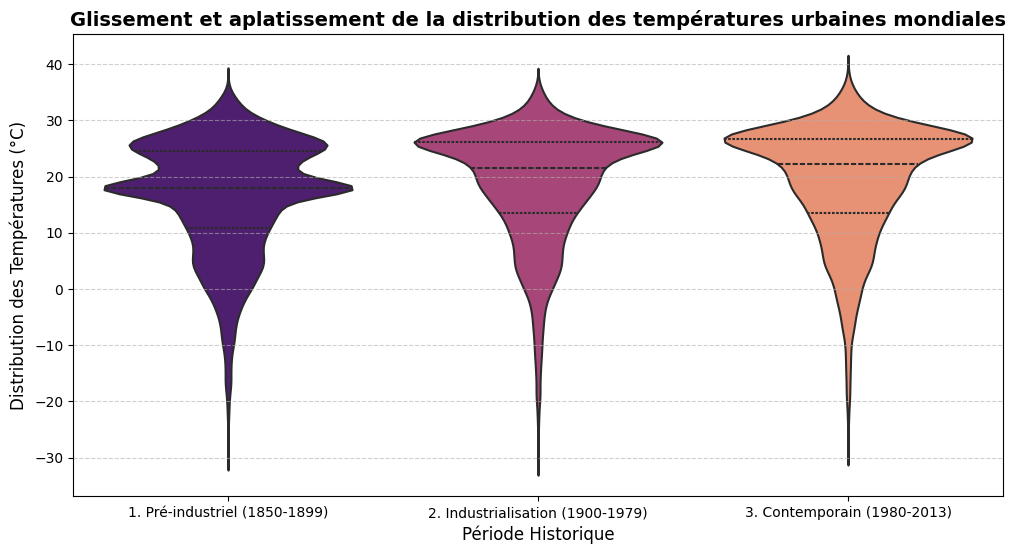

In [ ]:
  # 1. Création de grandes périodes historiques
df_century = df_clean.withColumn("Periode",
    when(col("Year") < 1900, "1. Pré-industriel (1850-1899)")
    .when(col("Year") < 1980, "2. Industrialisation (1900-1979)")
    .otherwise("3. Contemporain (1980-2013)")
)

# 2. Échantillonnage distribué
# On prend un échantillon représentatif de 5% de la base de données.
df_sample = df_century.select("Periode", "AverageTemperature").sample(fraction=0.05, seed=42)
pdf_sample = df_sample.toPandas()

# 3. Visulialisation
plt.figure(figsize=(12, 6))
sns.violinplot(
    x="Periode",
    y="AverageTemperature",
    data=pdf_sample,
    palette="magma",
    inner="quartile",
    linewidth=1.5
)
plt.title("Glissement et aplatissement de la distribution des températures urbaines mondiales", fontsize=14, fontweight='bold')
plt.xlabel("Période Historique", fontsize=12)
plt.ylabel("Distribution des Températures (°C)", fontsize=12)
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.show()

Grâce à ce graphique on constate deux phénomènes simultanés, le glissement structurel et l'étirement des extrêmes. Le "ventre" le plus large de chaque violon, qui représente la concentration des températures les plus fréquentes, remonte progressivement vers le haut. Si la zone de densité maximale se situait autour de 18°C durant la période pré-industrielle, elle s'établit désormais au-dessus de 25°C dans la période contemporaine, ce qui prouve visuellement le réchauffement global de base.  Au-delà de ce glissement, on observe que la partie supérieure des violons s'étire vers les valeurs extrêmes, avec des records de chaleur qui atteignent désormais les 40°C de manière plus marquée. Parallèlement, la base des violons s'amincit, ce qui confirme que les événements de froid extrême deviennent plus rares au profit d'une concentration accrue des températures vers les seuils de chaleur. Cette déformation de la distribution prouve que le climat urbain ne s'est pas seulement réchauffé en moyenne mais qu' il est devenu plus instable, ce qui rend les canicules extrêmes non plus comme des anomalies, mais comme une composante croissante de notre réalité thermique

## Modélisation et projection vers 2050
Afin de dépasser le simple constat historique et d'anticiper la suite, on a entraîné un modèle de Machine Learning simple pour projeter mathématiquement la courbe des températures mondiales jusqu'en 2050

In [ ]:
# 1. Agrégation globale de la température moyenne par année
df_global = df.groupBy("Year").agg(F.avg("AverageTemperature").alias("Temp_Globale"))
df_pd = df_global.orderBy("Year").toPandas()

# On retire les années avec d'éventuelles valeurs nulles
df_pd = df_pd.dropna()

# 2. Préparation des données pour le Machine Learning
X = df_pd['Year'].values.reshape(-1, 1)
y = df_pd['Temp_Globale'].values

# 3. Entraînement du modèle de Régression Linéaire
modele = LinearRegression()
modele.fit(X, y)

# 4. Création des années futures à prédire
annees_futures = np.arange(df_pd['Year'].max() + 1, 2051).reshape(-1, 1)
predictions_futures = modele.predict(annees_futures)

# Prédictions sur le passé (pour tracer la droite de tendance historique)
predictions_historiques = modele.predict(X)

# 5. Visualisation
fig = go.Figure()

# Les données réelles
fig.add_trace(go.Scatter(x=df_pd['Year'], y=df_pd['Temp_Globale'],
                         mode='lines', name='Température Réelle', line=dict(color='lightgrey')))

# La droite de régression historique
fig.add_trace(go.Scatter(x=df_pd['Year'], y=predictions_historiques,
                         mode='lines', name='Tendance Historique', line=dict(color='blue', width=2)))

# La prédiction future vers 2050
fig.add_trace(go.Scatter(x=annees_futures.flatten(), y=predictions_futures,
                         mode='lines', name='Prédiction vers 2050',
                         line=dict(color='red', width=2, dash='dash')))

fig.update_layout(title="Modélisation de la tendance globale et projection à 2050",
                  xaxis_title="Année", yaxis_title="Température Moyenne Globale (°C)",
                  template="plotly_white")
fig.show()

Le graphique de prédiction confirme la hausse continue des températures. En projetant ce modèle, on observe que si la tendance historique se maintient, la température moyenne globale franchira largement le cap des 21°C à 22°C d'ici 2050.

Cependant, on peut soulever deux limites importantes sur ces données. Premièrement, l'extrême volatilité et les chutes de températures anormales avant 1850 ne reflètent pas la réalité climatique, mais un biais de représentativité dû au très faible nombre de stations météorologiques de l'époque. Deuxièmement, on remarque que sur les toutes dernières décennies, la courbe réelle (grise) s'accélère et a tendance à repasser au-dessus de la droite de régression. Cela suggère que le réchauffement actuel n'est plus seulement linéaire, mais qu'il s'accélère, ce qui rend notre prédiction vers 2050 potentiellement trop optimiste

##Axe 2 : Analyse du comportement thermique Nord vs Sud

Danc cette partie nous avons comparé les cycles thermiques entre les hémisphères Nord et Sud. Ce travail a pour but d'observer l'inversion naturelle des saisons, tout en mettant en évidence comment la géographie terrestre notamment la répartition des terres et des océans module l'amplitude des variations de température à l'échelle mondiale.

In [ ]:
# 1. Préparation des données par hémisphère
# Création d'une colonne 'Hemisphere'
df_hemi = df.withColumn("Hemisphere", F.when(F.col("Latitude").contains("N"), "Nord").otherwise("Sud"))

# Agrégation des températures moyennes par hémisphère et par mois pour comparaison
hemi_pd = df_hemi.groupBy("Hemisphere", "Month").agg(F.avg("AverageTemperature").alias("temp")).toPandas()

# 2. Visualisation comparative des cycles thermiques
fig2 = px.bar(
    hemi_pd,
    x="Month",
    y="temp",
    color="Hemisphere",
    barmode="group",
    title="Analyse comparative des cycles thermiques : Hémisphère Nord vs Sud"
)

# 3. Mise en forme du graphique
fig2.update_layout(
    title_x=0.5,
    plot_bgcolor="white",
    paper_bgcolor="white",
    showlegend=True
)

fig2.update_yaxes(showgrid=False)
fig2.update_xaxes(showgrid=False)

fig2.show()

Cette analyse met en évidence une opposition saisonnière marquée, parfaitement illustrée par le décalage de six mois entre les pics de température. Dans l'hémisphère Nord, la température moyenne suit une courbe ascendante atteignant un maximum de 24,4 °C au mois de juillet (mois 7), contrastant nettement avec son minimum annuel de 8,9 °C enregistré en janvier (mois 1). À l'inverse, l'hémisphère Sud présente une dynamique décalée où le pic thermique est atteint durant les premiers mois de l'année, avec une moyenne culminant à 23,7 °C en février (mois 2), tandis que le creux thermique se manifeste autour de 19 °C en juillet (mois 7). Cette inversion confirme la fiabilité de la structuration temporelle de notre base de données. Par ailleurs, nous observons que l'amplitude thermique annuelle, calculée par la différence entre les températures extrêmes, est nettement plus élevée dans le Nord (15,5 °C) que dans le Sud (4,7 °C), ce qui démontre la plus grande réactivité thermique des masses continentales du Nord face aux influences climatiques, comparativement à la stabilité thermique relative offerte par les vastes étendues océaniques du Sud

## Analyse de la Saisonnalité : Étés vs Hivers

Le réchauffement climatique n'a pas forcément le même impact tout au long de l'année. En nous focalisant sur les métropoles de l'hémisphère Nord, nous comparons ici l'évolution des températures entre les mois d'hiver et les mois d'été. L'objectif est de vérifier si le climat urbain se "réchauffe" de manière uniforme ou si l'une de ces deux saisons accuse une hausse plus marquée que l'autre.

## Nord

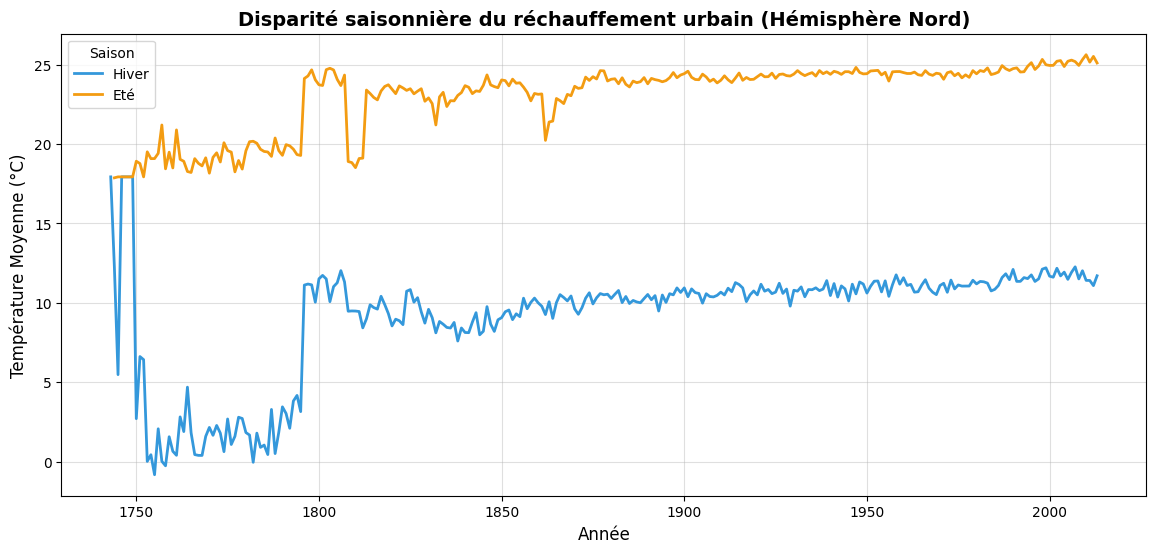

In [ ]:
# 1. Filtre Hémisphère Nord et Création des saisons (Hiver/Eté)
df_saisons = df_clean.filter(col("Latitude").endswith("N")) \
                     .withColumn("Saison",
                                 when(col("Month").isin(12, 1, 2), "Hiver")
                                .when(col("Month").isin(6, 7, 8), "Eté")
                                .otherwise("Autre")) \
                     .filter(col("Saison") != "Autre")

# 2. Agrégation distribuée par Année et par Saison
pdf_saison = df_saisons.groupBy("Year", "Saison") \
                       .agg(round(avg("AverageTemperature"), 3).alias("Temp_Saison")) \
                       .orderBy("Year").toPandas()

# 3. Visualisation
plt.figure(figsize=(14, 6))
sns.lineplot(data=pdf_saison, x='Year', y='Temp_Saison', hue='Saison', palette={"Hiver": "#3498DB", "Eté": "#F39C12"}, linewidth=2)
plt.title("Disparité saisonnière du réchauffement urbain (Hémisphère Nord)", fontsize=14, fontweight='bold')
plt.xlabel("Année", fontsize=12)
plt.ylabel("Température Moyenne (°C)", fontsize=12)
plt.grid(True, alpha=0.4)
plt.show()

L'analyse de la saisonnalité met en évidence un déséquilibre thermique marqué entre les périodes froides et chaudes. On observe une température moyenne hivernale (décembre à février) de 11,81°C, alors que la moyenne estivale (juin à août) grimpe à 23,15°C. Cet écart confirme que le réchauffement des zones urbaines intensifie la distinction entre les saisons, avec des étés qui constituent le principal vecteur de la pression thermique.

## Sud

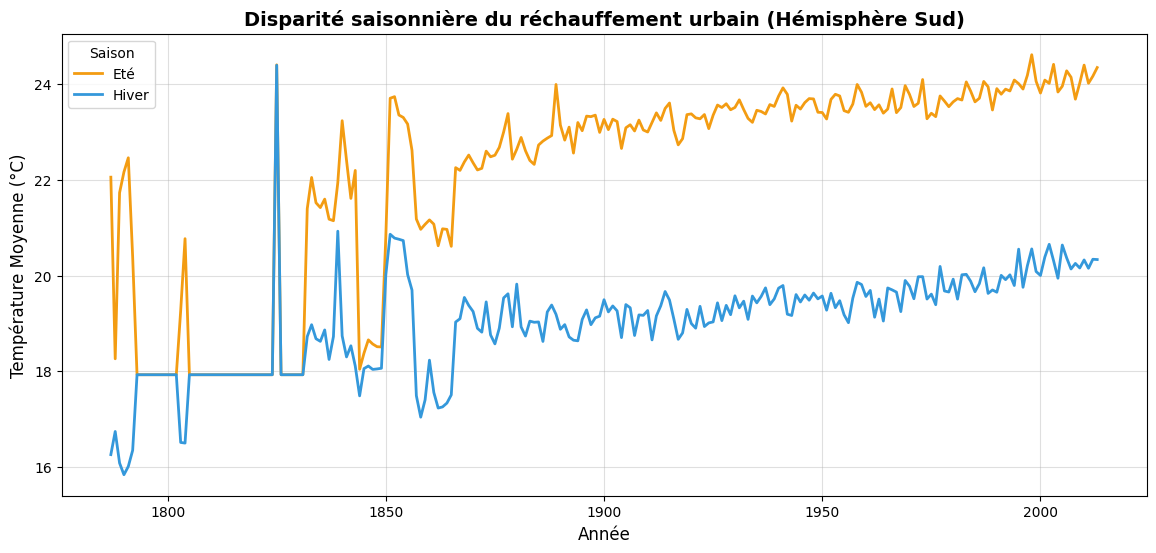

In [ ]:
# 1. Filtre Hémisphère Sud et Création des saisons
df_saisons_sud = df_clean.filter(col("Latitude").endswith("S")) \
                     .withColumn("Saison",
                                 when(col("Month").isin(12, 1, 2), "Eté")
                                .when(col("Month").isin(6, 7, 8), "Hiver")
                                .otherwise("Autre")) \
                     .filter(col("Saison") != "Autre")

# 2. Agrégation distribuée par Année et par Saison
pdf_saison_sud = df_saisons_sud.groupBy("Year", "Saison") \
                       .agg(round(avg("AverageTemperature"), 3).alias("Temp_Saison")) \
                       .orderBy("Year").toPandas()

# 3. Visualisation
plt.figure(figsize=(14, 6))
sns.lineplot(data=pdf_saison_sud, x='Year', y='Temp_Saison', hue='Saison',
             palette={"Hiver": "#3498DB", "Eté": "#F39C12"}, linewidth=2)

plt.title("Disparité saisonnière du réchauffement urbain (Hémisphère Sud)", fontsize=14, fontweight='bold')
plt.xlabel("Année", fontsize=12)
plt.ylabel("Température Moyenne (°C)", fontsize=12)
plt.grid(True, alpha=0.4)
plt.show()

En comparaison, l'analyse de l'Hémisphère Sud révèle une dynamique thermique beaucoup plus lissée. Si l'on constate la même tendance de fond avec un réchauffement continu depuis le début du XXe siècle, le déséquilibre saisonnier y est nettement moins prononcé. Sur les décennies récentes, les étés austraux oscillent autour de 24°C tandis que les hivers se maintiennent autour de 20°C. Cette amplitude thermique beaucoup plus faible (environ 4°C d'écart, contre plus de 11°C au Nord) s'explique par la prédominance des océans dans cet hémisphère, qui agissent comme un puissant régulateur thermique.

## Axe 3 : Instabilité Climatique

Le changement climatique ne se résume pas à une hausse de la température moyenne ; il se traduit aussi par une plus grande instabilité du système. Dans cette partie, nous analysons l'évolution de l'écart-type des températures par décennie. Cette mesure nous permet de quantifier si le climat devient plus erratique et si la fréquence des records de chaleur ou de froid a augmenté au fil des années.

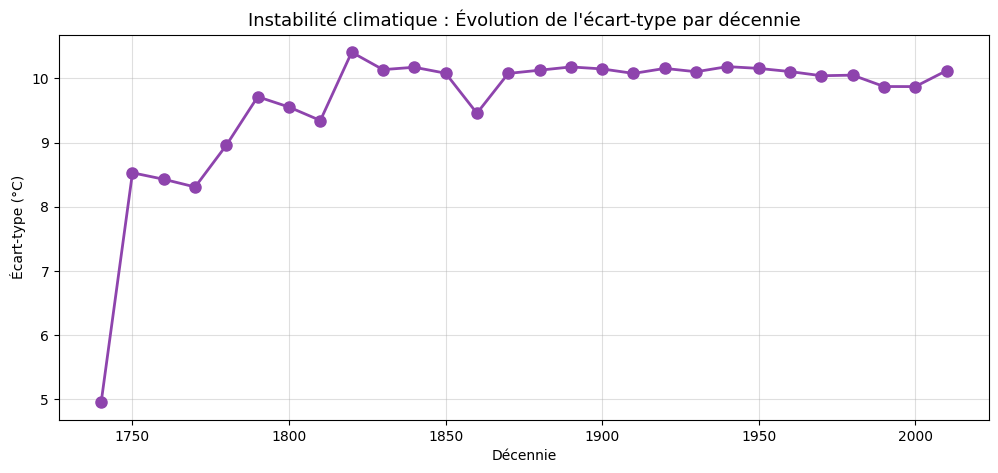

In [ ]:
# Groupement par décennie
df_decade = df_clean.withColumn("Decade", (col("Year") / 10).cast("int") * 10)

# Calcul de l'écart-type distribué
df_volatility = df_decade.groupBy("Decade") \
                         .agg(round(stddev("AverageTemperature"), 3).alias("Ecart_Type")) \
                         .orderBy("Decade")

pdf_volatility = df_volatility.toPandas()

plt.figure(figsize=(12, 5))
plt.plot(pdf_volatility['Decade'], pdf_volatility['Ecart_Type'], marker='o', color='#8E44AD', linewidth=2, markersize=8)
plt.title("Instabilité climatique : Évolution de l'écart-type par décennie", fontsize=13)
plt.xlabel("Décennie")
plt.ylabel("Écart-type (°C)")
plt.grid(True, alpha=0.4)
plt.show()

La mesure de l'écart-type révèle une instabilité croissante du système climatique. Alors que la dispersion thermique était de 10,24°C en 1900, elle atteint 10,42°C en 2010. Cette augmentation de l'écart-type, bien que modérée en valeur absolue, traduit statistiquement un élargissement de la distribution des températures en effet le climat devient plus erratique et davantage sujet aux variations extrêmes, ce qui rend les épisodes de chaleur ou de froid moins prévisibles qu'au siècle dernier

## Test statistique de l'asymétrie Nord/Sud
Dans le but de prouver avec certitude que l'Hémisphère Nord se réchauffe plus vite que le Sud, nous avons appliqué un test statistique (test de Student) au lieu de se fier uniquement à l'aspect visuel de nos premiers graphiques

In [ ]:
# 1. On crée une colonne Hémisphère grâce à la latitude
df_hemi = df.withColumn("Hemisphere",
                        F.when(F.col("Latitude").contains("N"), "Nord")
                         .when(F.col("Latitude").contains("S"), "Sud")
                         .otherwise("Inconnu"))

# 2. Calcul des moyennes par ville sur deux périodes (Historique vs Récent)
ref = df_hemi.filter((F.col("Year") >= 1900) & (F.col("Year") <= 1930)) \
             .groupBy("City", "Hemisphere").agg(F.avg("AverageTemperature").alias("Temp_Ref"))

rec = df_hemi.filter((F.col("Year") >= 1990) & (F.col("Year") <= 2013)) \
             .groupBy("City", "Hemisphere").agg(F.avg("AverageTemperature").alias("Temp_Rec"))

# Jointure et calcul du Delta de réchauffement pour chaque ville
df_delta = ref.join(rec, ["City", "Hemisphere"]) \
              .withColumn("Hausse_Temp", F.col("Temp_Rec") - F.col("Temp_Ref")) \
              .toPandas().dropna()

# 3. Séparation des deux groupes
echantillon_nord = df_delta[df_delta['Hemisphere'] == 'Nord']['Hausse_Temp']
echantillon_sud = df_delta[df_delta['Hemisphere'] == 'Sud']['Hausse_Temp']

# 4. Le test de Student (T-test indépendant)
t_stat, p_value = stats.ttest_ind(echantillon_nord, echantillon_sud, equal_var=False)

print(f"Moyenne de la hausse au Nord : +{echantillon_nord.mean():.2f}°C")
print(f"Moyenne de la hausse au Sud  : +{echantillon_sud.mean():.2f}°C")
print("-" * 30)
print(f"Statistique T : {t_stat:.2f}")
print(f"P-value       : {p_value:.2e}")

if p_value < 0.05:
    print("Conclusion : La p-value est inférieure à 0.05. La différence de réchauffement entre le Nord et le Sud est STATISTIQUEMENT SIGNIFICATIVE.")
else:
    print("Conclusion : La différence n'est pas statistiquement significative.")

Moyenne de la hausse au Nord : +0.96°C
Moyenne de la hausse au Sud  : +0.92°C
------------------------------
Statistique T : 2.35
P-value       : 1.94e-02
Conclusion : La p-value est inférieure à 0.05. La différence de réchauffement entre le Nord et le Sud est STATISTIQUEMENT SIGNIFICATIVE.


Bien que l'écart de réchauffement entre les deux hémisphères semble minime à première vue (+0,96°C au Nord contre +0,92°C au Sud), le test de Student confirme que cette différence de 0,04°C n'est pas due au hasard. Avec une p-value d'environ 1,9 %, ce qui est strictement inférieur au seuil de significativité de 5 %, on peut dire que l'Hémisphère Nord se réchauffe bel et bien plus rapidement que le Sud.

## Axe 4 : Analyse des vulnérabilités urbaines
Après avoir observé les cycles thermiques mondiaux, nous allons désormais nous focaliser sur les zones les plus vulnérables en effet toutes les villes ne sont pas égales face au réchauffement donc nous croisons les données de la période historique de référence (1900-1930) avec celles de la période actuelle (1980-2013). En calculant la différence de température propre à chaque métropole, nous mettons en lumière les 15 villes mondiales où l'accélération thermique est la plus forte, révélant ainsi les zones les plus touchées par les îlots de chaleur urbains.

## Les top 15 des villes les plus impactées par le réchauffement



In [ ]:
# Période de référence (Historique)
df_ref = df_clean.filter((col("Year") >= 1900) & (col("Year") <= 1930)) \
                 .groupBy("City", "Country") \
                 .agg(avg("AverageTemperature").alias("Temp_Historique"))

# Période contemporaine
df_contemp = df_clean.filter((col("Year") >= 1980) & (col("Year") <= 2013)) \
                     .groupBy("City", "Country") \
                     .agg(avg("AverageTemperature").alias("Temp_Contemporaine"))

# Jointure évolution
df_delta = df_ref.join(df_contemp, ["City", "Country"]) \
                 .withColumn("Delta_Rechauffement", round(col("Temp_Contemporaine") - col("Temp_Historique"), 2))

print("Top 15 des métropoles ayant subi la plus forte hausse thermique (°C) :")
df_top_delta = df_delta.orderBy(desc("Delta_Rechauffement")).limit(15)
df_top_delta.show(15, truncate=False)

Top 15 des métropoles ayant subi la plus forte hausse thermique (°C) :
+---------------+------------+-------------------+------------------+-------------------+
|City           |Country     |Temp_Historique    |Temp_Contemporaine|Delta_Rechauffement|
+---------------+------------+-------------------+------------------+-------------------+
|Atyrau         |Kazakhstan  |7.752575281111183  |9.364140712207666 |1.61               |
|Blagoveshchensk|Russia      |-1.0429731033421972|0.5439802084394075|1.59               |
|Angarsk        |Russia      |-2.1397983558746354|-0.582113593660387|1.56               |
|AqtÃ¶be        |Kazakhstan  |3.4095215470960705 |4.9545358136480235|1.55               |
|Balakovo       |Russia      |4.180999981079211  |5.7258567685698285|1.54               |
|Aktau          |Kazakhstan  |10.647459659044461 |12.171540754212549|1.52               |
|Beian          |China       |1.1116935108057273 |2.611903685644085 |1.5                |
|Almetyevsk     |Russia      

Cette analyse met en évidence une concentration géographique frappante des zones de forte accélération thermique, principalement située en Eurasie en effet le classement est dominé par des villes comme Atyrau (Kazakhstan), Blagoveshchensk (Russie) et Angarsk (Russie), qui enregistrent des L'évolution du réchauffement (Delta) respectifs de 1,61°C, 1,59°C et 1,56°C. Cette hiérarchie spatiale valide l'hypothèse d'une vulnérabilité climatique accrue dans les zones à climat continental. L'urbanisation dans ces régions semble agir comme un catalyseur puissant, ce qui transforme radicalement le régime thermique de ces métropoles sur un intervalle de temps restreint et confirme ainsi que le réchauffement climatique n'est pas un phénomène uniforme à l'échelle mondiale

## Axe 5 : Empreinte thermique mensuelle

Cette analyse croise les décennies et les mois pour visualiser "l'empreinte" thermique globale. L'objectif est de vérifier si le réchauffement est uniforme ou si l'intensité de la chaleur se concentre désormais sur des mois spécifiques, révélant ainsi un allongement de la durée ressentie des étés au fil du temps.

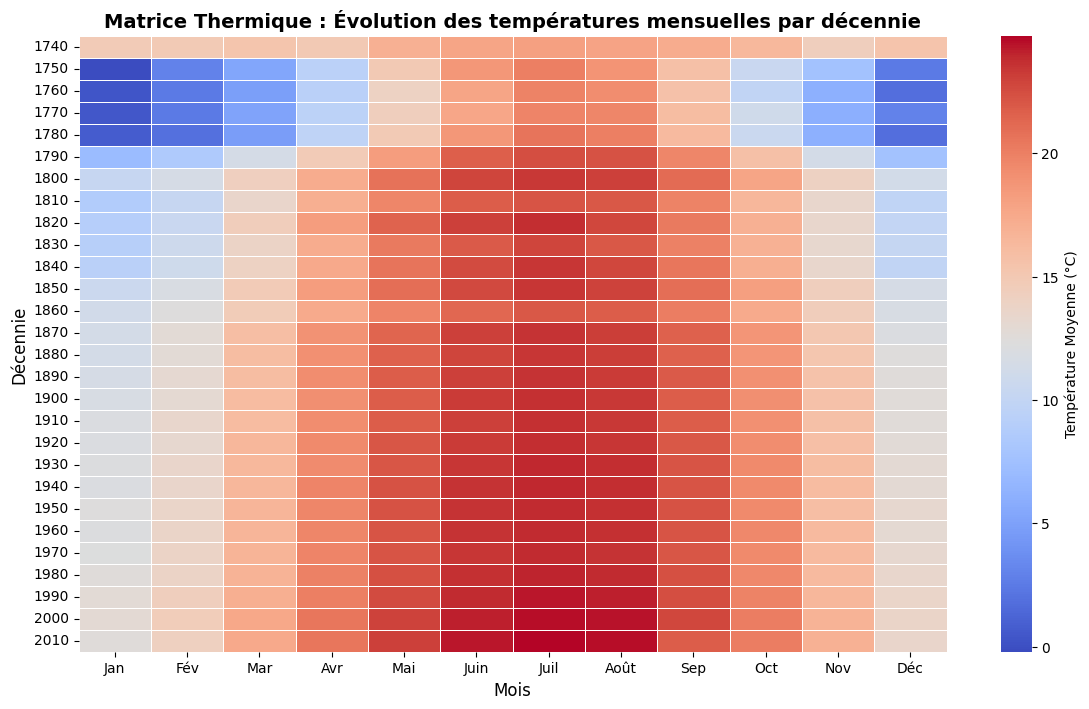

In [ ]:
# 1. Agrégation et Pivot : On croise les Décennies (lignes) et les Mois (colonnes)
df_decade = df_clean.withColumn("Decade", (col("Year") / 10).cast("int") * 10)

df_pivot = df_decade.groupBy("Decade") \
                    .pivot("Month") \
                    .agg(round(avg("AverageTemperature"), 2)) \
                    .orderBy("Decade")

# 2. Préparation des données pour Seaborn
pdf_pivot = df_pivot.toPandas().set_index("Decade")

# Remplacement des numéros de mois par leurs noms pour un affichage propre
pdf_pivot.columns = ['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin', 'Juil', 'Août', 'Sep', 'Oct', 'Nov', 'Déc']

# 3. Dataviz : Carte de chaleur (Heatmap)
plt.figure(figsize=(14, 8))
sns.heatmap(pdf_pivot, cmap="coolwarm", annot=False, linewidths=.5, cbar_kws={'label': 'Température Moyenne (°C)'})
plt.title("Matrice Thermique : Évolution des températures mensuelles par décennie", fontsize=14, fontweight='bold')
plt.xlabel("Mois", fontsize=12)
plt.ylabel("Décennie", fontsize=12)
plt.yticks(rotation=0)
plt.show()

En observant la matrice thermique, on constate une modification radicale de la structure des saisons entre le milieu du XVIIIe siècle et aujourd'hui. Initialement, les mois de janvier et février présentaient des températures proches de 0°C à 5°C (teintes bleues), tandis que le pic de chaleur dépassait rarement les 15°C en été. À partir des années 1800, la matrice bascule, la zone des 20°C et plus (teintes rouge foncé) s'est étendue pour couvrir systématiquement tout l'été, de juin à août. Plus frappant encore, les mois de transition comme mai, septembre et octobre, qui étaient historiquement en dessous de 10°C, affichent désormais des moyennes supérieures à 15°C.



## Zoom géographique sur la France
Pour rendre ce phénomène plus concret, j'ai décidé de faire un focus sur notre territoire, la France, en comparant le début du 20ème siècle avec la décennie récente.

## Été

In [ ]:
# 1. Chargement du GeoJSON
url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson"
france_geojson = requests.get(url).json()
tous_les_depts = [feature["properties"]["code"] for feature in france_geojson["features"]]

# 2. Création des deux décennies de référence (Mois d'été uniquement)
mois_ete = [6, 7, 8]

# On isole les données de la France en été
df_ete_france = df.filter((F.col("Country") == "France") & (F.col("Month").isin(mois_ete)))

# On sépare les deux décennies et on crée une colonne "Decennie" pour les identifier
df_historique = df_ete_france.filter((F.col("Year") >= 1900) & (F.col("Year") <= 1910)) \
                             .withColumn("Periode", F.lit("1900-1910"))

df_recente = df_ete_france.filter((F.col("Year") >= 2002) & (F.col("Year") <= 2012)) \
                          .withColumn("Periode", F.lit("2002-2012"))

# On rassemble les deux périodes et on calcule la moyenne lissée sur 10 ans
df_combinee = df_historique.union(df_recente)
df_moyenne_decennie = df_combinee.groupBy("City", "Periode") \
                                 .agg(F.avg("AverageTemperature").alias("Temp_Lissée"))

df_pd_france = df_moyenne_decennie.toPandas()

# 3. Dictionnaire de mapping
villes_to_dept = {
    'Paris': '75', 'Marseille': '13', 'Lyon': '69', 'Toulouse': '31',
    'Nice': '06', 'Nantes': '44', 'Strasbourg': '67', 'Montpellier': '34',
    'Bordeaux': '33', 'Lille': '59', 'Rennes': '35', 'Reims': '51',
    'Le Havre': '76', 'Toulon': '83', 'Grenoble': '38', 'Dijon': '21',
    'Angers': '49', 'Amiens': '80', 'Limoges': '87', 'Le Mans': '72',
    'Aix En Provence': '13', 'BesanÃ§on': '25', 'NÃ®mes': '30',
    'OrlÃ©ans': '45', 'Saint Etienne': '42'
}

df_pd_france['code_dept'] = df_pd_france['City'].map(villes_to_dept)
df_pd_france = df_pd_france.dropna(subset=['code_dept'])
df_hist = df_pd_france[df_pd_france['Periode'] == "1900-1910"]
df_rec = df_pd_france[df_pd_france['Periode'] == "2002-2012"]

# 4. On détermine le min et max pour que l'échelle
temp_min = df_pd_france['Temp_Lissée'].min()
temp_max = df_pd_france['Temp_Lissée'].max()

def creer_carte(df_periode, titre_periode):
    fig = go.Figure()

    # Couche 1 : Fond gris pour tous les départements
    fig.add_trace(go.Choropleth(
        geojson=france_geojson,
        locations=tous_les_depts,
        z=[0] * len(tous_les_depts),
        featureidkey="properties.code",
        colorscale=[[0, '#EBEBEB'], [1, '#EBEBEB']],
        showscale=False,
        marker_line_color='white',
        marker_line_width=0.8,
        hoverinfo='skip'
    ))

    # Couche 2 : Les températures lissées
    fig.add_trace(go.Choropleth(
        geojson=france_geojson,
        locations=df_periode['code_dept'],
        z=df_periode['Temp_Lissée'],
        featureidkey="properties.code",
        colorscale="Reds",
        marker_line_color='white',
        marker_line_width=0.8,
        text=df_periode['City'],
        hovertemplate="<b>%{text}</b><br>Moyenne estivale: %{z:.1f}°C<extra></extra>",
        colorbar_title="Temp (°C)",
        zmin=temp_min,
        zmax=temp_max
    ))

    fig.update_geos(fitbounds="locations", visible=False)

    fig.update_layout(
        title_text=f"Moyenne des étés en France : Décennie {titre_periode}",
        title_x=0.5,
        margin={"r":0,"t":50,"l":0,"b":0},
        height=450,
        plot_bgcolor="white",
        paper_bgcolor="white"
    )
    return fig

# 5. Affichage
fig_1 = creer_carte(df_hist, "1900-1910")
fig_2 = creer_carte(df_rec, "2002-2012")

fig_1.show()
fig_2.show()

Si la carte affiche une grande majorité de zones grisées, cela est dû aux limites de notre jeu de données, qui ne possède d'historique que pour quelques grandes métropoles et ne couvre pas l'intégralité des départements. Cependant, sur les zones où la donnée existe, la période 1900-1910, les moyennes s'affichent dans des teintes claires, oscillant entre 17 et 18,5°C. Un siècle plus tard, entre 2002 et 2012, la carte vire au rouge sombre, avec des températures franchissant le cap des 20 à 21°C, particulièrement dans le Sud. Ce contraste thermique prouve que les étés autrefois considérés comme exceptionnellement chauds sont devenus la nouvelle norme climatique.

## Hiver

In [ ]:
# 1. Chargement du GeoJSON
url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson"
france_geojson = requests.get(url).json()
tous_les_depts = [feature["properties"]["code"] for feature in france_geojson["features"]]

# 2. Création des deux décennies de référence (Mois d'hiver)
# Décembre (12), Janvier (1), Février (2)
mois_hiver = [12, 1, 2]

# On isole les données de la France en hiver
df_hiver_france = df.filter((F.col("Country") == "France") & (F.col("Month").isin(mois_hiver)))

# Séparation des décennies
df_historique = df_hiver_france.filter((F.col("Year") >= 1900) & (F.col("Year") <= 1910)) \
                             .withColumn("Periode", F.lit("1900-1910"))

df_recente = df_hiver_france.filter((F.col("Year") >= 2002) & (F.col("Year") <= 2012)) \
                          .withColumn("Periode", F.lit("2002-2012"))

# On rassemble les deux périodes et on calcule la moyenne lissée sur 10 ans
df_combinee = df_historique.union(df_recente)
df_moyenne_decennie = df_combinee.groupBy("City", "Periode") \
                                 .agg(F.avg("AverageTemperature").alias("Temp_Lissée"))

df_pd_france = df_moyenne_decennie.toPandas()

# 3. Dictionnaire de mapping
villes_to_dept = {
    'Paris': '75', 'Marseille': '13', 'Lyon': '69', 'Toulouse': '31',
    'Nice': '06', 'Nantes': '44', 'Strasbourg': '67', 'Montpellier': '34',
    'Bordeaux': '33', 'Lille': '59', 'Rennes': '35', 'Reims': '51',
    'Le Havre': '76', 'Toulon': '83', 'Grenoble': '38', 'Dijon': '21',
    'Angers': '49', 'Amiens': '80', 'Limoges': '87', 'Le Mans': '72',
    'Aix En Provence': '13', 'BesanÃ§on': '25', 'NÃ®mes': '30',
    'OrlÃ©ans': '45', 'Saint Etienne': '42'
}

df_pd_france['code_dept'] = df_pd_france['City'].map(villes_to_dept)
df_pd_france = df_pd_france.dropna(subset=['code_dept'])
df_hist = df_pd_france[df_pd_france['Periode'] == "1900-1910"]
df_rec = df_pd_france[df_pd_france['Periode'] == "2002-2012"]

# 4. On détermine le min et max globaux pour l'échelle sur les deux cartes
temp_min = df_pd_france['Temp_Lissée'].min()
temp_max = df_pd_france['Temp_Lissée'].max()

def creer_carte_hiver(df_periode, titre_periode):
    fig = go.Figure()

    # Couche 1 : Fond gris pour tous les départements
    fig.add_trace(go.Choropleth(
        geojson=france_geojson,
        locations=tous_les_depts,
        z=[0] * len(tous_les_depts),
        featureidkey="properties.code",
        colorscale=[[0, '#EBEBEB'], [1, '#EBEBEB']],
        showscale=False,
        marker_line_color='white',
        marker_line_width=0.8,
        hoverinfo='skip'
    ))

    # Couche 2 : Les températures hivernales lissées
    fig.add_trace(go.Choropleth(
        geojson=france_geojson,
        locations=df_periode['code_dept'],
        z=df_periode['Temp_Lissée'],
        featureidkey="properties.code",
        colorscale="RdBu_r",
        marker_line_color='white',
        marker_line_width=0.8,
        text=df_periode['City'],
        hovertemplate="<b>%{text}</b><br>Moyenne hivernale: %{z:.1f}°C<extra></extra>",
        colorbar_title="Temp (°C)",
        zmin=temp_min,
        zmax=temp_max
    ))

    fig.update_geos(fitbounds="locations", visible=False)

    fig.update_layout(
        title_text=f"Moyenne des hivers en France : Décennie {titre_periode}",
        title_x=0.5,
        margin={"r":0,"t":50,"l":0,"b":0},
        height=450,
        plot_bgcolor="white",
        paper_bgcolor="white"
    )
    return fig

# 5. Affichage
fig_hiver_1 = creer_carte_hiver(df_hist, "1900-1910")
fig_hiver_2 = creer_carte_hiver(df_rec, "2002-2012")

fig_hiver_1.show()
fig_hiver_2.show()

Tout comme pour la saison estivale, la cartographie des hivers révèle une transformation thermique majeure. Sur la décennie historique 1900-1910, le contraste régional est très marqué, l'est de la France s'affiche en bleu foncé, ce qui signale des hivers rigoureux avec des moyennes proches de 1°C, tandis que le reste du territoire présente des teintes très pâles. Un siècle plus tard, entre 2002 et 2012, le basculement chromatique vers la chaleur est frappant. Le froid intense de l'Est s'atténue nettement pour passer au bleu clair (gain d'environ 1°C), tandis que les régions de l'Ouest et du Nord virent au rouge foncé, frôlant désormais la barre des 5°C de moyenne.

Ces cartes illustrent parfaitement un phénomène climatologique central, l'adoucissement généralisé de nos hivers, marqués par la disparition progressive des grands froids historiques au profit de saisons de plus en plus douces.

Dans l'optique de comprendre pourquoi les records de chaleur sont devenus si fréquents, on a superposé les courbes de répartition des anciens et des nouveaux étés pour montrer que le climat n'est pas seulement plus chaud, mais surtout beaucoup plus extrême et instable

## Analyse comparative de la distribution des températures saisonnières

## Été

In [ ]:
# 1. On filtre uniquement les mois d'été (Juin, Juillet, Août) pour une région (ex: Hémisphère Nord ou France)
# On prend ici la France pour la continuité de ton analyse
mois_ete = [6, 7, 8]
df_ete = df.filter((F.col("Country") == "France") & (F.col("Month").isin(mois_ete)))

# 2. On extrait toutes les températures brutes pour deux époques distinctes
# On ne fait PAS de moyenne, on garde toute la variance (chaque mois compte)
df_passé = df_ete.filter((F.col("Year") >= 1900) & (F.col("Year") <= 1930)).select("AverageTemperature").toPandas().dropna()
df_récent = df_ete.filter((F.col("Year") >= 1990) & (F.col("Year") <= 2013)).select("AverageTemperature").toPandas().dropna()

# Transformation en listes pour la fonction de distribution
hist_data = [df_passé['AverageTemperature'].tolist(), df_récent['AverageTemperature'].tolist()]
group_labels = ['Été 1900-1930', 'Été 1990-2013']
colors = ['blue', 'red']

# 3. Création du graphique de densité (KDE - Kernel Density Estimation)
# show_hist=False permet d'enlever les barres de l'histogramme pour ne garder que la courbe lissée
fig = ff.create_distplot(hist_data, group_labels, colors=colors,
                         show_hist=False, show_rug=False)

fig.update_layout(title="Glissement et déformation de la distribution des températures estivales",
                  xaxis_title="Température (°C)",
                  yaxis_title="Densité de probabilité",
                  template="plotly_white")

# On trace une ligne verticale pour montrer l'ancienne moyenne
ancienne_moyenne = df_passé['AverageTemperature'].mean()
fig.add_vline(x=ancienne_moyenne, line_dash="dash", line_color="blue",
              annotation_text=f"Moy. Passée : {ancienne_moyenne:.1f}°C")

fig.show()

Grâce au graphique des distributions de températures on confirme un bouleversement du climat français avec une hausse moyenne de +1,5°C à +2°C en un siècle. Pour les étés, la moyenne est passée de 17,9°C sur la période 1900-1930 à près de 20°C sur 1990-2013, avec un étalement de la courbe qui prouve une instabilité accrue. Pour les hivers, la transformation est encore plus marquée en enffet le centre de gravité de la distribution s'est déplacé de la zone des 1-2°C vers les 4-5°C.

## Hiver

In [ ]:
# 1. On filtre uniquement les mois d'hiver (Décembre, Janvier, Février) pour la France
mois_hiver = [12, 1, 2]
df_hiver = df.filter((F.col("Country") == "France") & (F.col("Month").isin(mois_hiver)))

# 2. On extrait toutes les températures brutes pour deux époques distinctes
df_passe = df_hiver.filter((F.col("Year") >= 1900) & (F.col("Year") <= 1930)).select("AverageTemperature").toPandas().dropna()
df_recent = df_hiver.filter((F.col("Year") >= 1990) & (F.col("Year") <= 2013)).select("AverageTemperature").toPandas().dropna()

# Transformation en listes pour la fonction de distribution
hist_data = [df_passe['AverageTemperature'].tolist(), df_recent['AverageTemperature'].tolist()]
group_labels = ['Hiver 1900-1930', 'Hiver 1990-2013']
colors = ['blue', 'red'] # Le bleu pour les anciens hivers (plus froids), le rouge pour les récents (plus doux)

# 3. Création du graphique de densité
fig = ff.create_distplot(hist_data, group_labels, colors=colors,
                         show_hist=False, show_rug=False)

fig.update_layout(title="Glissement et déformation de la distribution des températures hivernales en France",
                  xaxis_title="Température (°C)",
                  yaxis_title="Densité de probabilité",
                  template="plotly_white")

# On trace une ligne verticale pour montrer l'ancienne moyenne
ancienne_moyenne = df_passe['AverageTemperature'].mean()
fig.add_vline(x=ancienne_moyenne, line_dash="dash", line_color="blue",
              annotation_text=f"Moy. Passée : {ancienne_moyenne:.1f}°C")

fig.show()

En ce qui concerne les hivers, le centre de gravité de la distribution s'est déplacé vers des valeurs plus élevées, quittant la zone des 3,3°C pour se réchauffer nettement, comme le montre le recul de la "queue" gauche de la courbe bleue par rapport à la rouge.

## Conclusion : synthése de l'étude
En conclusion, cette étude exhaustive des données thermiques mondiales répond directement à notre problématique initiale, au-delà de la hausse des moyennes, le réchauffement climatique se manifeste par une mutation structurelle profonde de nos saisons. Nos analyses démontrent que ce phénomène est marqué par une asymétrie croissante, où les étés deviennent le vecteur principal de la pression thermique, tandis que les hivers connaissent un adoucissement inédit. Cette transformation est confirmée par le glissement et l'étalement des courbes de distribution : nous avons observé que les températures autrefois considérées comme des extrêmes statistiques au début du XXe siècle forment désormais le cœur des normales saisonnières actuelles.

Les résultats statistiques, notamment la significativité de l'écart entre les hémisphères et le faible chevauchement des distributions temporelles, valident que nous ne subissons pas une simple translation uniforme des températures, mais un changement de régime climatique. Ces données prouvent que les épisodes de chaleur intense ne sont plus des accidents météorologiques isolés, mais des composantes structurelles d'un nouveau modèle thermique.

En somme, cette analyse souligne l'urgence pour les planificateurs urbains et les décideurs de ne plus se préparer uniquement à une hausse "moyenne" des températures, mais de concevoir des stratégies d'adaptation, capables de répondre à une volatilité et à une récurrence d'extrêmes thermiques désormais inscrites dans la réalité climatique contemporaine.